# Лабораторна робота № 2. Моделювання лінійних стаціонарних систем та обчислення дискретної згортки

### Мета: Засвоїти фундаментальні математичні засади функціонування лінійних стаціонарних дискретних (ЛСД) систем, отримати практичні навички алгоритмічної реалізації прямої лінійної та кругової (циклічної) згортки часових послідовностей, дослідити динамічні характеристики типових дискретних ланок (система ковзного середнього та дискретний диференціатор), а також опанувати методи розв'язання різницевих рівнянь другого порядку для знаходження імпульсної та перехідної характеристик.

#### *Варіант 2 (№ 22 у списку: $22 - 20 = 2$)*

### <div align="right">Виконав: Яцентюк Євгеній, група: КІ-24-1</div>
<div align="right">
  <a href="https://github.com/kefir4ikk"><b>GitHub</b></a>
</div>

## 1. Імпорт бібліотек та налаштування стилю відображення

In [1]:
import os
import json
import timeit
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

print(f"NumPy: {np.__version__} | SciPy: {__import__('scipy').__version__} | Matplotlib: {__import__('matplotlib').__version__}")

NumPy: 2.5.4 | SciPy: 1.18.1 | Matplotlib: 3.11.2


## 2. Параметри варіанта 2 та аналітичний розрахунок

**Вхідні дані (варіант 2):**

- $x[n]=[1,\,3,\,-2,\,2,\,0,\,1,\,-1,\,4]$, $N_x=8$; $\;h[n]=[2,\,-1,\,0,\,2]$, $N_h=4$;
- різницеве рівняння 2-го порядку, $[a_1,a_2,b_0,b_1,b_2]=[-0.7,\,0.12,\,0.8,\,-0.4,\,0.2]$:
  $$y[n]-0.7\,y[n-1]+0.12\,y[n-2]=0.8\,x[n]-0.4\,x[n-1]+0.2\,x[n-2];$$
- тестові імпульси: прямокутний $x_{rect}[n]=u[n]-u[n-6]$ ($L_{rect}=6$) та експоненційний $x_{exp}[n]=1.5\cdot 0.8^{n}u[n]$ ($A=1.5$, $\alpha=0.8$);
- довжина ковзного середнього $M=5$: $h_{ma}[n]=\frac15\sum_{k=0}^{4}\delta[n-k]$; диференціатор $y[n]=x[n]-x[n-1]$.

**Лінійна згортка:** $y[n]=\sum_{k}x[k]\,h[n-k]$, довжина результату $N_y=N_x+N_h-1=8+4-1=11$.

**Кругова згортка:** $y_c[n]=\sum_{m=0}^{N-1}x[m]\,h[(n-m)\bmod N]$. Для збігу з лінійною потрібно $N\ge N_x+N_h-1=11$.

**Аналітичний розрахунок перших чотирьох тактів лінійної згортки:**

| $n$ | $y[n]=\sum x[k]h[n-k]$ | $y[n]$ |
|:-:|:--|:-:|
| 0 | $x[0]h[0]=1\cdot2$ | **2** |
| 1 | $x[0]h[1]+x[1]h[0]=1\cdot(-1)+3\cdot2$ | **5** |
| 2 | $x[0]h[2]+x[1]h[1]+x[2]h[0]=1\cdot0+3\cdot(-1)+(-2)\cdot2$ | **−7** |
| 3 | $x[0]h[3]+x[1]h[2]+x[2]h[1]+x[3]h[0]=1\cdot2+3\cdot0+(-2)\cdot(-1)+2\cdot2$ | **8** |

**Аналіз стійкості системи 2-го порядку:** характеристичне рівняння $z^2-0.7z+0.12=0$, $D=0.49-0.48=0.01$, полюси $z_{1,2}=\dfrac{0.7\pm0.1}{2}$, тобто $z_1=0.4$, $z_2=0.3$. Обидва полюси лежать усередині одиничного кола ($|z_i|<1$) — система стійка. Усталене значення перехідної характеристики $g[\infty]=H(1)=\dfrac{0.8-0.4+0.2}{1-0.7+0.12}=\dfrac{0.6}{0.42}\approx1.4286$.

In [2]:
# Параметри варіанта 2
x = np.array([1, 3, -2, 2, 0, 1, -1, 4], dtype=float)
h = np.array([2, -1, 0, 2], dtype=float)
a1, a2, b0, b1, b2 = -0.7, 0.12, 0.8, -0.4, 0.2
L_rect, A_exp, alpha = 6, 1.5, 0.8
M_ma = 5

Nx, Nh = len(x), len(h)
Ny = Nx + Nh - 1                      # довжина лінійної згортки

# Аналітичний розрахунок перших чотирьох тактів: y[n] = sum_k x[k] h[n-k]
y_analytic = np.array([
    x[0] * h[0],
    x[0] * h[1] + x[1] * h[0],
    x[0] * h[2] + x[1] * h[1] + x[2] * h[0],
    x[0] * h[3] + x[1] * h[2] + x[2] * h[1] + x[3] * h[0],
])
print(f"Nx = {Nx}, Nh = {Nh}, Ny = Nx + Nh - 1 = {Ny}")
print("Аналітично y[0..3] =", y_analytic)

Nx = 8, Nh = 4, Ny = Nx + Nh - 1 = 11
Аналітично y[0..3] = [ 2.  5. -7.  8.]


## 3. Лінійна згортка: власний алгоритм та порівняння з NumPy / SciPy

Власна реалізація виконує для кожного $n$ підсумовування лише за допустимими індексами $k$: $\max(0,\,n-N_h+1)\le k\le\min(n,\,N_x-1)$. Загальна кількість множень дорівнює $N_x\cdot N_h$, тобто складність алгоритму $O(N_x N_h)$.

ПОРІВНЯЛЬНИЙ АНАЛІЗ РЕАЛІЗАЦІЙ ЛІНІЙНОЇ ДИСКРЕТНОЇ ЗГОРТКИ
x[n] (N=8): [ 1.  3. -2.  2.  0.  1. -1.  4.]
h[n] (N=4): [ 2. -1.  0.  2.]
y_custom:     [ 2.  5. -7.  8.  4. -2.  1.  9. -2. -2.  8.]
np.convolve:  [ 2.  5. -7.  8.  4. -2.  1.  9. -2. -2.  8.]
scipy.signal: [ 2.  5. -7.  8.  4. -2.  1.  9. -2. -2.  8.]
Кількість множень: 32 (Nx*Nh = 32)
Час власного алгоритму: 10.67 мкс
Час numpy.convolve:     1.28 мкс
Час scipy.convolve:     4.35 мкс
Макс. відхилення від NumPy: 0.00e+00; від SciPy: 0.00e+00
Перші 4 такти збігаються з аналітичним розрахунком: y[0..3] = [ 2.  5. -7.  8.]


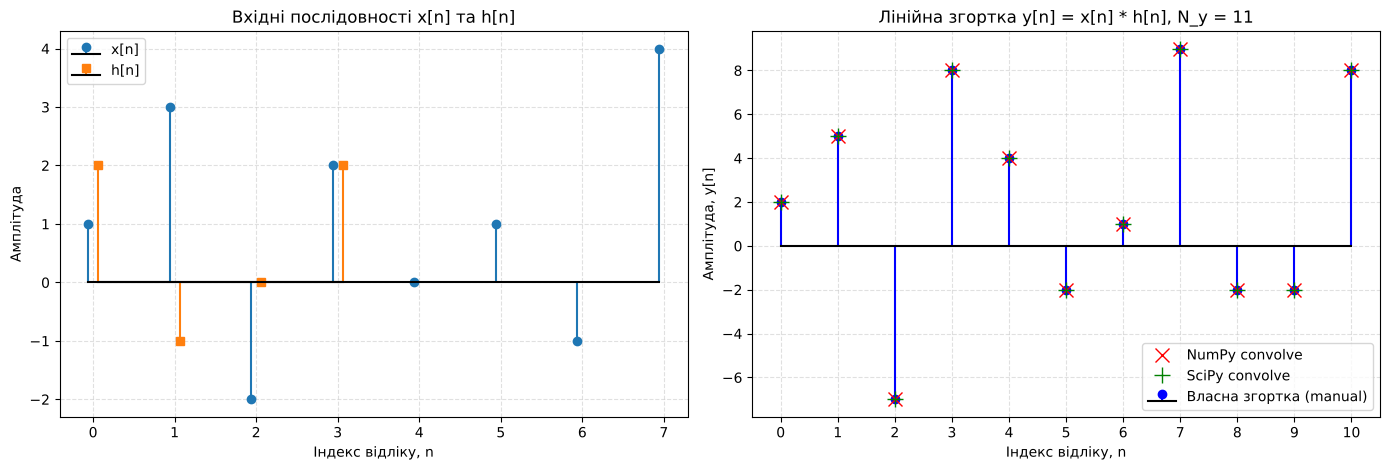

In [3]:
def manual_linear_convolution(x_seq, h_seq):
    """
    Пряме обчислення лінійної дискретної згортки (обертання, зсув, перемноження, сумування):
    y[n] = sum_k x[k] * h[n - k],  0 <= n < Nx + Nh - 1
    """
    len_x, len_h = len(x_seq), len(h_seq)
    y_out = np.zeros(len_x + len_h - 1, dtype=float)
    for n in range(len(y_out)):
        acc = 0.0
        # допустимі k: 0 <= k < Nx та 0 <= n-k < Nh
        for k in range(max(0, n - len_h + 1), min(n, len_x - 1) + 1):
            acc += x_seq[k] * h_seq[n - k]
        y_out[n] = acc
    return y_out

y_custom = manual_linear_convolution(x, h)
y_numpy = np.convolve(x, h, mode='full')
y_scipy = signal.convolve(x, h, mode='full', method='direct')

# Кількість множень у власному алгоритмі
n_mults = sum(min(n, Nx - 1) - max(0, n - Nh + 1) + 1 for n in range(Ny))

# Час виконання (мінімум із 5 серій по 2000 викликів)
def t_us(f):
    return min(timeit.repeat(f, number=2000, repeat=5)) / 2000 * 1e6
t_custom = t_us(lambda: manual_linear_convolution(x, h))
t_numpy = t_us(lambda: np.convolve(x, h, mode='full'))
t_scipy = t_us(lambda: signal.convolve(x, h, mode='full', method='direct'))

diff_np = np.max(np.abs(y_custom - y_numpy))
diff_sc = np.max(np.abs(y_custom - y_scipy))

print("=" * 65)
print("ПОРІВНЯЛЬНИЙ АНАЛІЗ РЕАЛІЗАЦІЙ ЛІНІЙНОЇ ДИСКРЕТНОЇ ЗГОРТКИ")
print(f"x[n] (N={Nx}): {x}")
print(f"h[n] (N={Nh}): {h}")
print(f"y_custom:     {y_custom}")
print(f"np.convolve:  {y_numpy}")
print(f"scipy.signal: {y_scipy}")
print(f"Кількість множень: {n_mults} (Nx*Nh = {Nx * Nh})")
print(f"Час власного алгоритму: {t_custom:.2f} мкс")
print(f"Час numpy.convolve:     {t_numpy:.2f} мкс")
print(f"Час scipy.convolve:     {t_scipy:.2f} мкс")
print(f"Макс. відхилення від NumPy: {diff_np:.2e}; від SciPy: {diff_sc:.2e}")
print("=" * 65)

# Перевірка збігу з аналітичним розрахунком перших чотирьох тактів
assert np.allclose(y_custom[:4], y_analytic), "Розбіжність з аналітичним розрахунком!"
assert np.allclose(y_custom, y_numpy) and np.allclose(y_custom, y_scipy)
print("Перші 4 такти збігаються з аналітичним розрахунком: y[0..3] =", y_custom[:4])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
nx_axis, nh_axis, ny_axis = np.arange(Nx), np.arange(Nh), np.arange(Ny)
ax = axes[0]
ax.stem(nx_axis - 0.06, x, linefmt='C0-', markerfmt='C0o', basefmt='k-', label='x[n]')
ax.stem(nh_axis + 0.06, h, linefmt='C1-', markerfmt='C1s', basefmt='k-', label='h[n]')
ax.set_title("Вхідні послідовності x[n] та h[n]")
ax.set_xlabel("Індекс відліку, n"); ax.set_ylabel("Амплітуда")
ax.set_xticks(nx_axis); ax.grid(True); ax.legend()

ax = axes[1]
ax.stem(ny_axis, y_custom, linefmt='b-', markerfmt='bo', basefmt='k-', label='Власна згортка (manual)')
ax.plot(ny_axis, y_numpy, 'rx', markersize=10, label='NumPy convolve')
ax.plot(ny_axis, y_scipy, 'g+', markersize=12, label='SciPy convolve')
ax.set_title(f"Лінійна згортка y[n] = x[n] * h[n], N_y = {Ny}")
ax.set_xlabel("Індекс відліку, n"); ax.set_ylabel("Амплітуда, y[n]")
ax.set_xticks(ny_axis); ax.grid(True); ax.legend()
plt.tight_layout()
plt.savefig("figures/linear_vs_builtin_conv.png", dpi=200)
plt.show()

## 4. Елементарні ЛСД-системи: ковзне середнє та диференціатор

Ковзне середнє: $h_{ma}[n]=\frac1M\sum_{k=0}^{M-1}\delta[n-k]$, $M=5$ (НЧ-фільтр, затримка $(M-1)/2=2$ такти). Диференціатор: $h_{diff}[n]=\delta[n]-\delta[n-1]$ (ВЧ-ланка). Відгуки знаходимо як $y[n]=x[n]*h[n]$.

MA, прямокутний імпульс:    [0.2 0.4 0.6 0.8 1.  1.  0.8 0.6 0.4 0.2 0.  0.  0.  0.  0.  0. ]
MA, експоненційний імпульс: [0.3   0.54  0.732 0.886 1.008 0.807 0.645 0.516 0.413 0.33  0.264 0.211
 0.169 0.135 0.108 0.087]
Диф., прямокутний імпульс:  [ 1.  0.  0.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
Диф., експоненційний імп.:  [ 1.5   -0.3   -0.24  -0.192 -0.154 -0.123 -0.098 -0.079 -0.063 -0.05
 -0.04  -0.032 -0.026 -0.021 -0.016 -0.013]

MA: плато рівня 1 на відліках n = [4, 5] (L - M + 1 = 2)
MA(exp): максимум 1.008 при n = 4 (вхід: максимум 1.50 при n = 0)
Диф.(exp): y[0] = 1.50, y[1] = -0.30 (аналітично A(alpha-1) = -0.30)


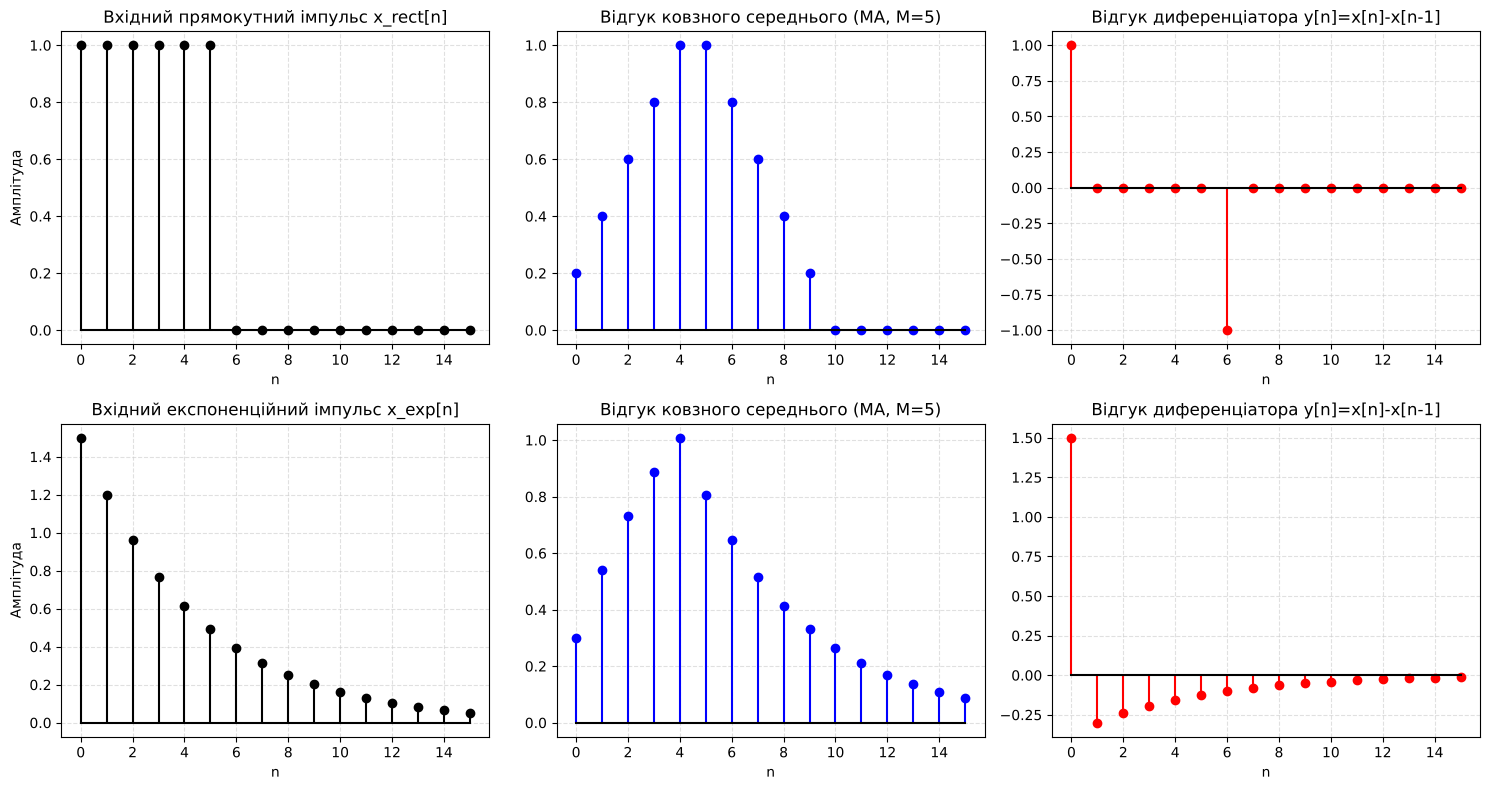

In [4]:
n_pts = 16
n_arr = np.arange(n_pts)

x_rect = np.where(n_arr < L_rect, 1.0, 0.0)           # прямокутний імпульс, L = 6
x_exp = A_exp * alpha ** n_arr                         # експоненційний імпульс 1.5 * 0.8^n

h_ma = np.ones(M_ma) / M_ma                            # ковзне середнє, M = 5
h_diff = np.array([1.0, -1.0])                         # диференціатор y[n] = x[n] - x[n-1]

resp = lambda xin, hin: signal.convolve(xin, hin, mode='full')[:n_pts]
y_ma_rect, y_ma_exp = resp(x_rect, h_ma), resp(x_exp, h_ma)
y_diff_rect, y_diff_exp = resp(x_rect, h_diff), resp(x_exp, h_diff)

print("MA, прямокутний імпульс:   ", np.round(y_ma_rect, 3))
print("MA, експоненційний імпульс:", np.round(y_ma_exp, 3))
print("Диф., прямокутний імпульс: ", np.round(y_diff_rect, 3))
print("Диф., експоненційний імп.: ", np.round(y_diff_exp, 3))

# Перевірка за аналітичними формулами
assert np.allclose(y_ma_rect[:M_ma], (np.arange(M_ma) + 1) / M_ma)                  # лінійне наростання (n+1)/M
assert np.isclose(y_diff_rect[0], 1) and np.isclose(y_diff_rect[L_rect], -1)         # стрибки +1 (n=0) та -1 (n=L)
assert np.allclose(y_diff_exp[1:], A_exp * alpha ** (n_arr[1:] - 1) * (alpha - 1))   # y[n] = A a^(n-1) (a-1)

plateau = np.where(np.isclose(y_ma_rect, 1.0))[0]
print(f"\nMA: плато рівня 1 на відліках n = {plateau.tolist()} (L - M + 1 = {L_rect - M_ma + 1})")
print(f"MA(exp): максимум {y_ma_exp.max():.3f} при n = {int(np.argmax(y_ma_exp))} (вхід: максимум {x_exp.max():.2f} при n = 0)")
print(f"Диф.(exp): y[0] = {y_diff_exp[0]:.2f}, y[1] = {y_diff_exp[1]:.2f} (аналітично A(alpha-1) = {A_exp * (alpha - 1):.2f})")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
rows = [("прямокутний імпульс x_rect[n]", x_rect, y_ma_rect, y_diff_rect),
        ("експоненційний імпульс x_exp[n]", x_exp, y_ma_exp, y_diff_exp)]
for i, (name, xin, ym, yd) in enumerate(rows):
    axes[i, 0].stem(n_arr, xin, linefmt='k-', markerfmt='ko', basefmt='k-')
    axes[i, 0].set_title(f"Вхідний {name}"); axes[i, 0].set_ylabel("Амплітуда")
    axes[i, 1].stem(n_arr, ym, linefmt='b-', markerfmt='bo', basefmt='k-')
    axes[i, 1].set_title(f"Відгук ковзного середнього (MA, M={M_ma})")
    axes[i, 2].stem(n_arr, yd, linefmt='r-', markerfmt='ro', basefmt='k-')
    axes[i, 2].set_title("Відгук диференціатора y[n]=x[n]-x[n-1]")
    for ax in axes[i]:
        ax.set_xlabel("n"); ax.grid(True)
plt.tight_layout()
plt.savefig("figures/elementary_systems_resp.png", dpi=200)
plt.show()

## 5. Система 2-го порядку: імпульсна та перехідна характеристики

Рекурентна форма: $y[n]=b_0x[n]+b_1x[n-1]+b_2x[n-2]-a_1y[n-1]-a_2y[n-2]$. Імпульсна характеристика $h[n]$ — відгук на $\delta[n]$, перехідна $g[n]$ — відгук на $u[n]$, при цьому $g[n]=\sum_{k=0}^{n}h[k]$. Результат верифікуємо через `scipy.signal.lfilter`.

ВЕРИФІКАЦІЯ СИСТЕМИ 2-ГО ПОРЯДКУ
h[n], n=0..7 (direct): [0.8    0.16   0.216  0.132  0.0665 0.0307 0.0135 0.0058]
h[n], n=0..7 (SciPy):  [0.8    0.16   0.216  0.132  0.0665 0.0307 0.0135 0.0058]
Розбіжність h: 0.00e+00; розбіжність g: 4.44e-16
g[n], n=0..7 (direct): [0.8    0.96   1.176  1.308  1.3745 1.4052 1.4187 1.4245]

Полюси: [0.3 0.4]; |z| < 1: True -> система стійка
Нулі:   [0.25+0.433j 0.25-0.433j]
g[inf] = H(1) = 1.4286; g[24] = 1.4286; |h[24]| = 1.18e-09


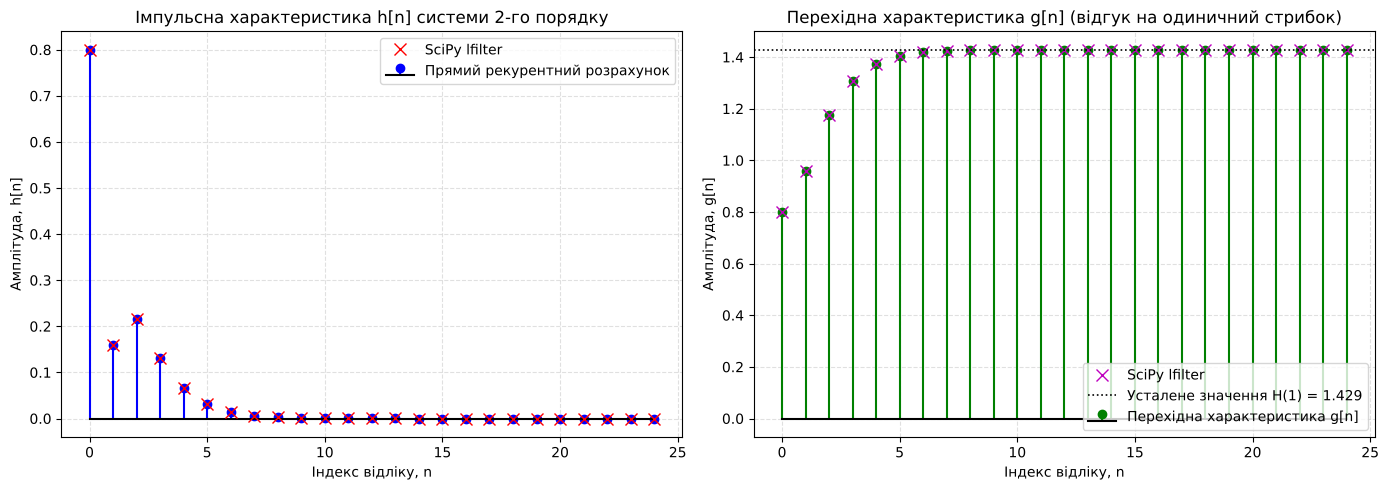

In [5]:
b_coeffs = np.array([b0, b1, b2])          # 0.8, -0.4, 0.2
a_coeffs = np.array([1.0, a1, a2])         # 1, -0.7, 0.12

def simulate_difference_equation(b, a, x_input):
    """
    Пряме рекурентне обчислення виходу за різницевим рівнянням:
    y[n] = (1/a0) * ( sum_m b[m] x[n-m] - sum_{k>=1} a[k] y[n-k] )
    """
    y_output = np.zeros(len(x_input), dtype=float)
    for n in range(len(x_input)):
        acc_x = sum(b[m] * x_input[n - m] for m in range(len(b)) if n - m >= 0)
        acc_y = sum(a[k] * y_output[n - k] for k in range(1, len(a)) if n - k >= 0)
        y_output[n] = (acc_x - acc_y) / a[0]
    return y_output

N_sim = 25
n_sim = np.arange(N_sim)
delta_in = np.zeros(N_sim); delta_in[0] = 1.0       # одиничний імпульс
step_in = np.ones(N_sim)                            # одиничний стрибок

h_sim = simulate_difference_equation(b_coeffs, a_coeffs, delta_in)
g_sim = simulate_difference_equation(b_coeffs, a_coeffs, step_in)
h_scipy = signal.lfilter(b_coeffs, a_coeffs, delta_in)
g_scipy = signal.lfilter(b_coeffs, a_coeffs, step_in)

poles = np.roots(a_coeffs)                          # z^2 + a1 z + a2 = 0
zeros_ = np.roots(b_coeffs)
stable = bool(np.all(np.abs(poles) < 1))
g_inf = b_coeffs.sum() / a_coeffs.sum()             # H(1)

print("ВЕРИФІКАЦІЯ СИСТЕМИ 2-ГО ПОРЯДКУ")
print("h[n], n=0..7 (direct):", np.round(h_sim[:8], 4))
print("h[n], n=0..7 (SciPy): ", np.round(h_scipy[:8], 4))
print(f"Розбіжність h: {np.max(np.abs(h_sim - h_scipy)):.2e}; розбіжність g: {np.max(np.abs(g_sim - g_scipy)):.2e}")
print("g[n], n=0..7 (direct):", np.round(g_sim[:8], 4))
print(f"\nПолюси: {np.round(np.sort(poles.real), 4)}; |z| < 1: {stable} -> система {'стійка' if stable else 'нестійка'}")
print(f"Нулі:   {np.round(zeros_, 4)}")
print(f"g[inf] = H(1) = {g_inf:.4f}; g[{N_sim - 1}] = {g_sim[-1]:.4f}; |h[{N_sim - 1}]| = {abs(h_sim[-1]):.2e}")

assert np.allclose(h_sim, h_scipy) and np.allclose(g_sim, g_scipy)
assert np.allclose(g_sim, np.cumsum(h_sim))         # g[n] = sum h[k]
assert np.isclose(h_sim[0], b0) and np.isclose(h_sim[1], b1 - a1 * b0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].stem(n_sim, h_sim, linefmt='b-', markerfmt='bo', basefmt='k-', label='Прямий рекурентний розрахунок')
axes[0].plot(n_sim, h_scipy, 'rx', markersize=8, label='SciPy lfilter')
axes[0].set_title("Імпульсна характеристика h[n] системи 2-го порядку")
axes[0].set_xlabel("Індекс відліку, n"); axes[0].set_ylabel("Амплітуда, h[n]")
axes[0].grid(True); axes[0].legend()

axes[1].stem(n_sim, g_sim, linefmt='g-', markerfmt='go', basefmt='k-', label='Перехідна характеристика g[n]')
axes[1].plot(n_sim, g_scipy, 'mx', markersize=8, label='SciPy lfilter')
axes[1].axhline(g_inf, color='k', ls=':', lw=1.2, label=f'Усталене значення H(1) = {g_inf:.3f}')
axes[1].set_title("Перехідна характеристика g[n] (відгук на одиничний стрибок)")
axes[1].set_xlabel("Індекс відліку, n"); axes[1].set_ylabel("Амплітуда, g[n]")
axes[1].grid(True); axes[1].legend(loc='lower right')
plt.tight_layout()
plt.savefig("figures/system_2nd_order_resp.png", dpi=200)
plt.show()

## 6. Кругова згортка та перехід до лінійної через доповнення нулями (zero-padding)

Кругова згортка довжини $N$ «згортає» лінійний результат за модулем $N$: $y_c[n]=\sum_{j}y[n+jN]$ (часовий аліасинг). При $N=N_x=8<N_y=11$ перші три відліки спотворюються сумою $y[n]+y[n+8]$, $n=0,1,2$. Мінімальна довжина періоду для збігу з лінійною згорткою $L=N_x+N_h-1=11$, тобто до $x[n]$ додаємо 3 нулі, до $h[n]$ — 7 нулів.

Лінійна згортка (N_y=11):    [ 2.  5. -7.  8.  4. -2.  1.  9. -2. -2.  8.]
Кругова згортка, N = 8:      [ 0.  3.  1.  8.  4. -2.  1.  9.]
Кругова згортка, N = L = 11: [ 2.  5. -7.  8.  4. -2.  1.  9. -2. -2.  8.]

Аліасинг: y_c[0..2] = y[0..2] + y[8..10] = [ 2.  5. -7.] + [-2. -2.  8.] = [0. 3. 1.]
Перевірка через ШПФ (L = 11): max|y_fft - y_lin| = 1.78e-15

 N | max|y_c - y_lin| | збіг з лінійною
 8 |             8.00 | ні
 9 |             8.00 | ні
10 |             8.00 | ні
11 |             0.00 | так
12 |             0.00 | так
13 |             0.00 | так


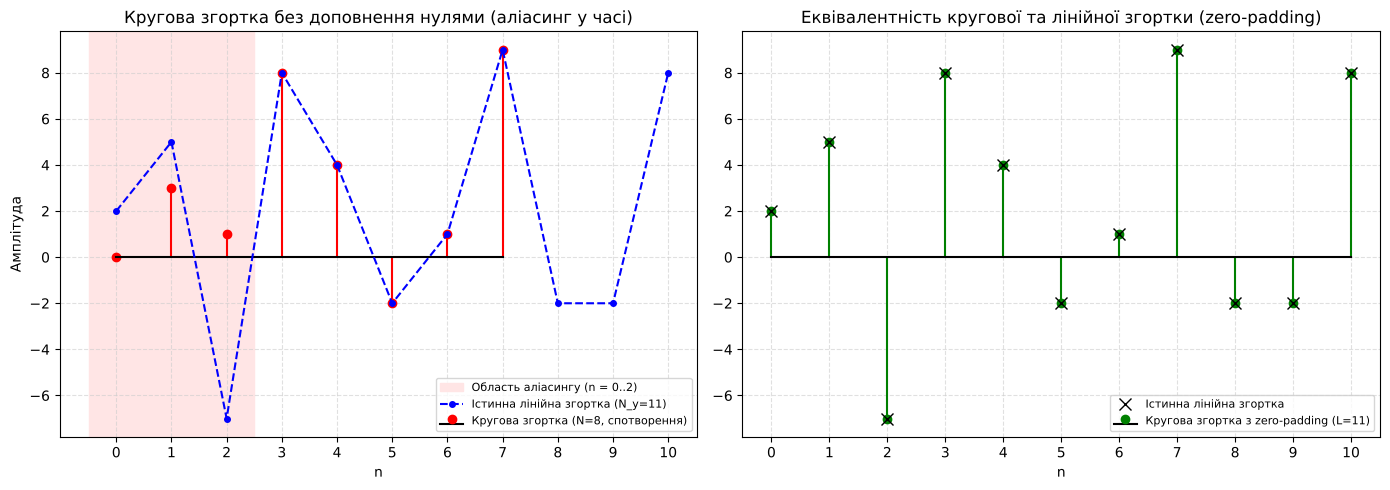

In [6]:
def manual_circular_convolution(x_seq, h_seq, N=None):
    """
    Кругова (циклічна) згортка довжини N з доповненням нулями:
    y_c[n] = sum_{m=0}^{N-1} x[m] * h[(n - m) mod N]
    """
    if N is None:
        N = max(len(x_seq), len(h_seq))
    x_pad = np.pad(x_seq, (0, N - len(x_seq)))
    h_pad = np.pad(h_seq, (0, N - len(h_seq)))
    y_circ = np.zeros(N, dtype=float)
    for n in range(N):
        acc = 0.0
        for m in range(N):
            acc += x_pad[m] * h_pad[(n - m) % N]
        y_circ[n] = acc
    return y_circ

def fold(y, N):
    """Згортання лінійного результату за модулем N: sum_j y[n + jN]."""
    out = np.zeros(N)
    for n, v in enumerate(y):
        out[n % N] += v
    return out

y_lin = y_custom                                             # лінійна згортка (11 відліків)
y_c8 = manual_circular_convolution(x, h)                     # N = 8 (без доповнення нулями)
L_pad = Nx + Nh - 1                                          # L = 11
y_c11 = manual_circular_convolution(x, h, N=L_pad)           # N = L = 11 (zero-padding)

print("Лінійна згортка (N_y=11):   ", y_lin)
print("Кругова згортка, N = 8:     ", y_c8)
print("Кругова згортка, N = L = 11:", y_c11)
print(f"\nАліасинг: y_c[0..2] = y[0..2] + y[8..10] = {y_lin[:3]} + {y_lin[8:]} = {y_lin[:3] + y_lin[8:]}")

assert np.allclose(y_c8, fold(y_lin, 8))                     # кругова = згорнута лінійна
assert np.allclose(y_c8[3:], y_lin[3:8])                     # відліки n=3..7 не спотворені
assert np.allclose(y_c11, y_lin)                             # при L >= Nx+Nh-1 збігається з лінійною

# Перевірка через ШПФ: y = IFFT( FFT(x, L) * FFT(h, L) )
y_fft = np.fft.ifft(np.fft.fft(x, L_pad) * np.fft.fft(h, L_pad)).real
print(f"Перевірка через ШПФ (L = {L_pad}): max|y_fft - y_lin| = {np.max(np.abs(y_fft - y_lin)):.2e}")

# Залежність похибки від довжини періоду N
print("\n N | max|y_c - y_lin| | збіг з лінійною")
err_by_N = {}
for N in range(8, 14):
    yc = manual_circular_convolution(x, h, N=N)
    ref = np.zeros(N); ref[:min(N, Ny)] = y_lin[:N]
    err = float(np.max(np.abs(yc - ref)))
    err_by_N[N] = err
    print(f"{N:2d} | {err:16.2f} | {'так' if err < 1e-9 else 'ні'}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.axvspan(-0.5, 2.5, color='#ffe5e5', label='Область аліасингу (n = 0..2)')
ax.stem(np.arange(8), y_c8, linefmt='r-', markerfmt='ro', basefmt='k-', label='Кругова згортка (N=8, спотворення)')
ax.plot(np.arange(Ny), y_lin, 'b--o', markersize=4, label='Істинна лінійна згортка (N_y=11)')
ax.set_title("Кругова згортка без доповнення нулями (аліасинг у часі)")
ax.set_xlabel("n"); ax.set_ylabel("Амплітуда"); ax.set_xticks(np.arange(Ny)); ax.grid(True); ax.legend(fontsize=8)

ax = axes[1]
ax.stem(np.arange(L_pad), y_c11, linefmt='g-', markerfmt='go', basefmt='k-', label=f'Кругова згортка з zero-padding (L={L_pad})')
ax.plot(np.arange(Ny), y_lin, 'kx', markersize=9, label='Істинна лінійна згортка')
ax.set_title("Еквівалентність кругової та лінійної згортки (zero-padding)")
ax.set_xlabel("n"); ax.set_xticks(np.arange(Ny)); ax.grid(True); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/circular_vs_linear_conv.png", dpi=200)
plt.show()

## 7. Часова складність прямого алгоритму згортки

Для підтвердження оцінки $O(N_x N_h)$ вимірюємо час власної реалізації в двох режимах: (а) $N_x=N_h=N$ (очікується квадратичне зростання, нахил у log–log масштабі ≈ 2, при подвоєнні $N$ час зростає приблизно вчетверо); (б) $N_h=4$ = const (очікується лінійне зростання, нахил ≈ 1). Для порівняння наведено `np.convolve`.

Нахил log-log (Nx = Nh = N): 2.06  (теорія: 2)
Відношення часу при подвоєнні N (400 -> 800): 4.17  (теорія: 4)
Нахил log-log (Nh = 4):      1.02  (теорія: 1)
N =   50: manual =     0.48 мс, множень = 2500
N =  100: manual =     1.85 мс, множень = 10000
N =  200: manual =     7.27 мс, множень = 40000
N =  400: manual =    30.39 мс, множень = 160000
N =  800: manual =   126.86 мс, множень = 640000


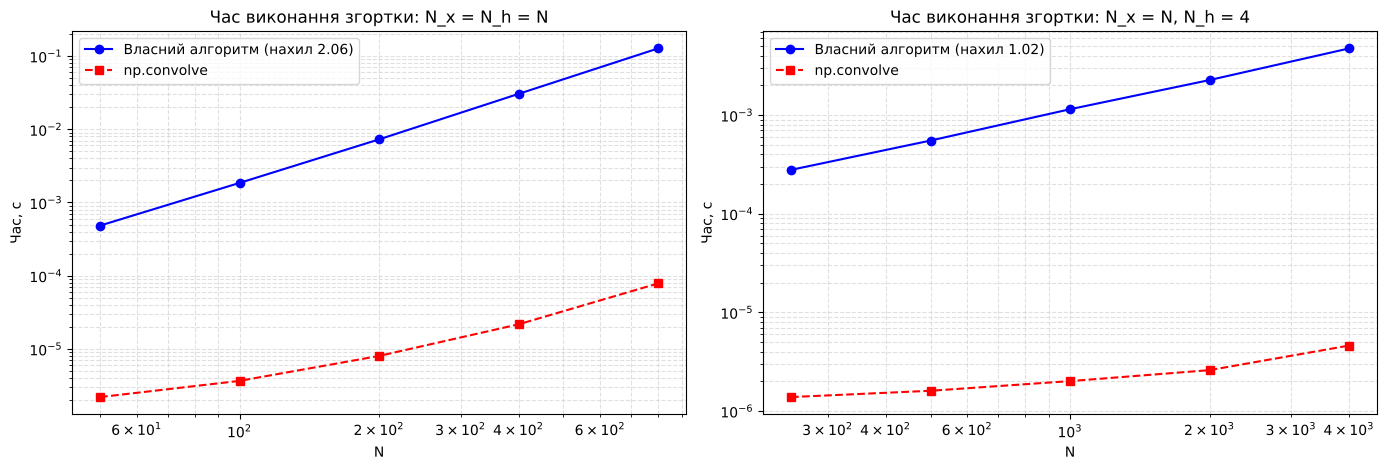

In [7]:
rng = np.random.default_rng(0)

def best_time(f, number=1, repeat=3):
    return min(timeit.repeat(f, number=number, repeat=repeat)) / number

sizes_sq = [50, 100, 200, 400, 800]               # Nx = Nh = N
sizes_lin = [250, 500, 1000, 2000, 4000]          # Nx = N, Nh = 4
t_sq, t_np_sq, t_ln, t_np_ln = [], [], [], []
for N in sizes_sq:
    xa, ha = rng.standard_normal(N), rng.standard_normal(N)
    t_sq.append(best_time(lambda: manual_linear_convolution(xa, ha)))
    t_np_sq.append(best_time(lambda: np.convolve(xa, ha), number=50))
for N in sizes_lin:
    xa, ha = rng.standard_normal(N), rng.standard_normal(4)
    t_ln.append(best_time(lambda: manual_linear_convolution(xa, ha)))
    t_np_ln.append(best_time(lambda: np.convolve(xa, ha), number=200))

# нахил оцінюємо за трьома найбільшими N, щоб прибрати вплив накладних витрат інтерпретатора на малих N
slope_sq = np.polyfit(np.log(sizes_sq[-3:]), np.log(t_sq[-3:]), 1)[0]
slope_ln = np.polyfit(np.log(sizes_lin[-3:]), np.log(t_ln[-3:]), 1)[0]
print(f"Нахил log-log (Nx = Nh = N): {slope_sq:.2f}  (теорія: 2)")
print(f"Відношення часу при подвоєнні N (400 -> 800): {t_sq[-1] / t_sq[-2]:.2f}  (теорія: 4)")
print(f"Нахил log-log (Nh = 4):      {slope_ln:.2f}  (теорія: 1)")
for N, t in zip(sizes_sq, t_sq):
    print(f"N = {N:4d}: manual = {t * 1e3:8.2f} мс, множень = {N * N}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, sizes, tm, tn, sl, ttl in [
        (axes[0], sizes_sq, t_sq, t_np_sq, slope_sq, "N_x = N_h = N"),
        (axes[1], sizes_lin, t_ln, t_np_ln, slope_ln, "N_x = N, N_h = 4")]:
    ax.loglog(sizes, tm, 'bo-', label=f'Власний алгоритм (нахил {sl:.2f})')
    ax.loglog(sizes, tn, 'rs--', label='np.convolve')
    ax.set_title(f"Час виконання згортки: {ttl}")
    ax.set_xlabel("N"); ax.set_ylabel("Час, с"); ax.grid(True, which='both'); ax.legend()
plt.tight_layout()
plt.savefig("figures/complexity_benchmark.png", dpi=200)
plt.show()

## 8. Експорт результатів

In [8]:
# Згортка: лінійна та кругова (N = 8 і N = L = 11)
y_c8_col = np.concatenate([y_c8, np.full(Ny - len(y_c8), np.nan)])
np.savetxt("data/convolution.csv",
           np.column_stack([np.arange(Ny), y_lin, y_c8_col, y_c11]),
           delimiter=",", header="n,y_linear,y_circular_N8,y_circular_L11", comments="")

# Система 2-го порядку: імпульсна та перехідна характеристики
np.savetxt("data/system_2nd_order.csv",
           np.column_stack([n_sim, h_sim, g_sim]),
           delimiter=",", header="n,h_n,g_n", comments="")

results = dict(
    variant=2,
    x=x.tolist(), h=h.tolist(),
    coeffs=dict(a1=a1, a2=a2, b0=b0, b1=b1, b2=b2),
    y_linear=y_lin.tolist(), y_circular_N8=y_c8.tolist(), y_circular_L11=y_c11.tolist(),
    y_first4_analytic=y_analytic.tolist(),
    t_manual_us=t_custom, t_numpy_us=t_numpy, t_scipy_us=t_scipy,
    max_diff_numpy=float(diff_np), max_diff_scipy=float(diff_sc),
    poles=[float(p.real) for p in np.sort_complex(poles)], stable=stable, g_inf=float(g_inf),
    h_first8=h_sim[:8].tolist(), g_first8=g_sim[:8].tolist(),
    ma_rect=y_ma_rect.tolist(), ma_exp=y_ma_exp.tolist(),
    diff_rect=y_diff_rect.tolist(), diff_exp=y_diff_exp.tolist(),
    circular_error_by_N=err_by_N,
    complexity_slope_square=float(slope_sq), complexity_slope_linear=float(slope_ln),
)
with open("data/results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=1)
print("Готово: figures/, data/")

Готово: figures/, data/


## Висновки

1. **Лінійна згортка.** Для $x[n]=[1,3,-2,2,0,1,-1,4]$ і $h[n]=[2,-1,0,2]$ отримано $y[n]=[2,5,-7,8,4,-2,1,9,-2,-2,8]$, $N_y=N_x+N_h-1=11$. Власний алгоритм збігається з аналітичним розрахунком перших чотирьох тактів ($2,\,5,\,-7,\,8$), а також із `np.convolve` та `scipy.signal.convolve` (максимальне відхилення $0$). Прямий алгоритм виконує $N_x N_h$ множень (тут 32), тобто має складність $O(N_xN_h)$: експеримент підтвердив квадратичне зростання при $N_x=N_h=N$ (нахил у log–log масштабі ≈ 2, подвоєння $N$ збільшує час приблизно вчетверо) та лінійне при $N_h=\mathrm{const}$ (нахил ≈ 1). Бібліотечні реалізації швидші завдяки векторизації (на цих даних `np.convolve` приблизно в 10 разів, `scipy.signal.convolve` приблизно в 3 рази швидші за власну); для довгих послідовностей застосовують згортку через ШПФ зі складністю $O(N\log N)$.
2. **Ковзне середнє ($M=5$)** — фільтр нижніх частот: $\sum h_{ma}=1$, тому постійна складова проходить без зміни, а різкі перепади згладжуються. Прямокутний імпульс ($L=6$) перетворюється на трапецію тривалістю $L+M-1=10$ відліків: фронт і спад по $M=5$ відліків (крок $1/M=0{,}2$), плато рівня 1 на $L-M+1=2$ відліках ($n=4,5$), сума відліків зберігається ($=6$). Центр імпульсу зміщується на $(M-1)/2=2$ такти. Експоненційний імпульс втрачає різкий початковий пік: максимум знижується з 1,5 до 1,008 і зсувається з $n=0$ на $n=4$.
3. **Диференціатор $y[n]=x[n]-x[n-1]$** — фільтр верхніх частот ($\sum h_{diff}=0$, постійна складова повністю гаситься). На прямокутному імпульсі він дає лише два відліки: $+1$ при $n=0$ (фронт) і $-1$ при $n=6$ (спад), на плато відгук нульовий, тобто диференціатор виділяє стрибки сигналу. Для експоненційного імпульсу $y[0]=A=1{,}5$, далі $y[n]=A\alpha^{n-1}(\alpha-1)=-0{,}3\cdot0{,}8^{n-1}$ — від'ємна експонента, бо сигнал спадає.
4. **Система 2-го порядку.** Полюси $z_1=0{,}4$, $z_2=0{,}3$ (збігаються з аналітичним розрахунком), $|z_i|<1$ — система стійка, відгук без коливань. Імпульсна характеристика $h[n]=0{,}8;\;0{,}16;\;0{,}216;\;0{,}132;\;0{,}0665;\dots$ нескінченна (НІХ), оскільки ненульові $a_1,a_2$ створюють зворотний зв'язок; вона затухає як $0{,}4^n$ ($|h[24]|\approx10^{-9}$). Перехідна характеристика $g[n]=\sum_{k\le n}h[k]$ монотонно прямує до $H(1)=0{,}6/0{,}42\approx1{,}4286$ ($g[24]=1{,}4286$). Рекурентний розрахунок збігається з `scipy.signal.lfilter` з точністю до $10^{-16}$.
5. **Кругова згортка.** При $N=N_x=8<N_y=11$ виникає часовий аліасинг: $y_c[n]=y[n]+y[n+8]$ для $n=0,1,2$, тобто $y_c=[0,3,1,8,4,-2,1,9]$ замість $[2,5,-7,\dots]$; відліки $n=3\dots7$ не спотворені. Кругова згортка збігається з лінійною тоді й лише тоді, коли $N\ge N_x+N_h-1=11$ (потрібно додати 3 нулі до $x[n]$ і 7 нулів до $h[n]$): для $N=11,12,13$ похибка дорівнює 0, а вже для $N=10$ максимальна похибка становить 8. Той самий результат дає $\mathrm{IFFT}\{\mathrm{FFT}\{x\}\cdot\mathrm{FFT}\{h\}\}$ при $L=11$ (розбіжність $\sim10^{-15}$), що є основою швидкої згортки через ДПФ.

## Контрольні питання:

### 1. Сформулюйте математичні критерії лінійності та стаціонарності для дискретних систем обробки сигналів



Нехай система описується оператором перетворення $T\{\cdot\}$, тобто $y[n] = T\{x[n]\}$.

* **Критерій лінійності (принцип суперпозиції):**
Система є лінійною, якщо для будь-яких вхідних сигналів $x_1[n]$, $x_2[n]$ та довільних констант $a, b \in \mathbb{C}$ виконується:

$$T\{a \cdot x_1[n] + b \cdot x_2[n]\} = a \cdot T\{x_1[n]\} + b \cdot T\{x_2[n]\} = a \cdot y_1[n] + b \cdot y_2[n]$$



Це об'єднує властивості адитивності та однорідності (масштабування).
* **Критерій стаціонарності (інваріантності до зсуву в часі):**
Система є стаціонарною, якщо часовий зсув вхідного сигналу на будь-яку цілу кількість тактів $n_0$ призводить до аналогічного зсуву вихідного сигналу без спотворення його форми:

$$T\{x[n - n_0]\} = y[n - n_0], \quad \forall n_0 \in \mathbb{Z}$$



---

### 2. Чому імпульсна характеристика $h[n]$ є вичерпним описом лінійної стаціонарної дискретної системи у часовій області?




Імпульсна характеристика $h[n] = T\{\delta[n]\}$ повністю визначає поведінку LTI-системи завдяки двом факторам:

1. **Розклад вхідного сигналу:** Будь-який довільний сигнал $x[n]$ можна розкласти у зважену суму зміщених одиничних імпульсів Кронекера:

$$x[n] = \sum_{k=-\infty}^{\infty} x[k] \delta[n - k]$$


2. **Лінійність та стаціонарність:**
* Завдяки **стаціонарності**, реакція системи на зміщений імпульс $\delta[n - k]$ дорівнює зміщеній імпульсній характеристиці $h[n - k]$.
* Завдяки **лінійності**, реакція на суму зважених імпульсів дорівнює сумі відповідних реакцій:

$$y[n] = T\{x[n]\} = T\left\{ \sum_{k=-\infty}^{\infty} x[k] \delta[n - k] \right\} = \sum_{k=-\infty}^{\infty} x[k] T\{\delta[n - k]\} = \sum_{k=-\infty}^{\infty} x[k] h[n - k]$$





Оскільки реакція системи на довільний вхідний сигнал однозначно обчислюється через дискретну згортку $y[n] = x[n] * h[n]$, знання однієї лише $h[n]$ повністю описує динаміку системи.

---

### 3. Яким чином визначається результуюча тривалість лінійної згортки двох скінченних послідовностей довжиною $N_x$ та $N_h$?




Результуюча тривалість (кількість ненульових відліків) $L$ визначається формулою:


$$L = N_x + N_h - 1$$

*Обґрунтування:* Якщо послідовність $x[n]$ існує на інтервалі індексів $n \in [0, N_x - 1]$, а $h[n]$ — на інтервалі $n \in [0, N_h - 1]$, то перший ненульовий відлік згортки з'являється при $n = 0 + 0 = 0$, а останній — при $n = (N_x - 1) + (N_h - 1) = N_x + N_h - 2$. Загальна кількість відліків становить:


$$(N_x + N_h - 2) - 0 + 1 = N_x + N_h - 1$$

---

### 4. У чому полягає відмінність між фізичним змістом операцій лінійної та кругової (циклічної) дискретної згортки?




* **Лінійна згортка:** Моделює фізичний процес проходження сигналу через динамічну систему в реальному часі. Сигнали вважаються аперіодичними (дорівнюють нулю поза межами свого інтервалу визначення). Зсув одного сигналу відносно іншого є лінійним, через що вихідний сигнал розширюється в часі ($L = N_x + N_h - 1$).
* **Кругова (циклічна) згортка:** Є математичним результатом множення дискретних спектрів у частотній області (через ДПФ / ШПФ). Вона розглядає послідовності як періодичні з періодом $N$ (або визначені на колі довжиною $N$). Зсув здійснюється за модулем $N$ ($n \pmod N$). Через це хвіст вихідного сигналу, який виходить за межі довжини $N$, "зациклюється" і накладається на його початок (виникає часовий аліасинг / time-domain aliasing).

---

### 5. Яку мінімальну кількість нульових відліків (Zero-Padding) необхідно додати до вхідних послідовностей, щоб результат кругової згортки збігався з лінійною?




Розмірність кругової згортки $N$ має бути не меншою за повну тривалість лінійної згортки:


$$N \ge N_x + N_h - 1$$

Відповідно, мінімальна кількість нулів, яку потрібно дописати в кінець кожної послідовності:

* До послідовності $x[n]$: $N - N_x = (N_x + N_h - 1) - N_x = \mathbf{N_h - 1}$ відліків.
* До послідовності $h[n]$: $N - N_h = (N_x + N_h - 1) - N_h = \mathbf{N_x - 1}$ відліків.

Обидва сигнали доповнюються нулями до однакової загальної довжини не менше $N_x + N_h - 1$.

---

### 6. Як впливає система ковзного середнього (Moving Average) на високочастотні та низькочастотні складові вхідного сигналу?




Система ковзного середнього є найпростішим **фільтром низьких частот (ФНЧ)**:

* **Низькочастотні складові:** Пропускаються майже без змін. Сигнал, що повільно змінюється в межах вікна усереднення, має близькі за значенням сусідні відліки, тому їхнє середнє практично дорівнює самому сигналу.
* **Високочастотні складові:** Суттєво пригнічуються (згладжуються). Швидкі коливання та шум часто мають чергування знаків або різкі перепади на інтервалі вікна, тому при додаванні вони взаємно компенсуються, що знижує амплітуду шуму та швидких гармонік.

---

### 7. Чому наявність ненульових коефіцієнтів зворотного зв'язку $a_k$ ($k \ge 1$) у різницевому рівнянні призводить до виникнення нескінченної імпульсної характеристики (НІХ)?




Різницеве рівняння дискретної системи має вигляд:


$$y[n] = \sum_{m=0}^{M} b_m x[n - m] - \sum_{k=1}^{N} a_k y[n - k]$$

Якщо на вхід подається одиничний імпульс $x[n] = \delta[n]$:

1. За наявності коефіцієнтів $a_k \ne 0$, розрахунок поточного відліку $y[n]$ є **рекурсивним** — він використовує попередні вихідні значення $y[n-k]$.
2. Після моменту $n > M$ вхідні відліки $\delta[n - m]$ стають рівними нулю, проте зворотний зв'язок продовжує циркулювати: значення $y[n]$, обчислені на попередніх кроках, повертаються на вхід системи та генерують наступні значення $y[n + 1], y[n + 2], \dots$.
3. У стійкій системі ця рекурсія приводить до експоненційного затухання вихідного відгуку, проте теоретично вихід прямує до нуля нескінченно довго і не перетворюється на точний нуль за скінченну кількість тактів. Це зумовлює нескінченну довжину $h[n]$.